# Week 6, Task 5: Smoothing the switches

**Question.** In Task 3.1 the forward-mode gradient of 6-hour global-mean OLR with respect to uniform SST warming was about 0.39 W m⁻² K⁻¹, while the finite difference gave 0.32–0.34 (about 15% lower). At a 1-day window the gap grew to about 2.3×. Does that gap shrink when SPEEDY's on/off switches are given smooth derivatives? If it doesn't, what else could explain it?

**Recipe (same as Task 3):** build J, check it against a finite difference, then make a map.

**How smoothing works in JCM 3.0.** Each `*_smoothing` parameter is a *surrogate-derivative* half-width. The model's **values are unchanged**: the switch still flips hard. Only the derivative is replaced by the derivative of a smooth function of that width, so a gradient can "see" columns that are near a threshold. The parameters live in `jcm.physics.speedy.params.Parameters` and are passed in through `speedy_physics(parameters=...)`:

| parameter | where | units |
|---|---|---|
| `convection.trigger_smoothing` | boundary-layer RH trigger for deep convection | RH fraction |
| `shortwave_radiation.cover_smoothing` | cloud-cover hinges/clips (RH hinge, cover ≤ 1, stratiform, √precip) | cover/RH fraction |
| `convection.precnv_smoothing` | convective-precip onset | g m⁻² s⁻¹ |
| `condensation.cap_smoothing` | large-scale condensation heating cap | fraction of cap |
| `vertical_diffusion.rh_gate_smoothing` / `mse_gate_smoothing` | shallow-convection gates | RH fraction / J kg⁻¹ |
| `surface_flux.evap_smoothing` | soil-moisture evaporation hinge (land only) | g kg⁻¹ |

## 0. Setup

In [14]:
import jax, jax.numpy as jnp, numpy as np
print(jax.devices())   # should show a GPU

[CudaDevice(id=0)]


In [15]:
import os, time
from importlib.resources import files
import matplotlib.pyplot as plt
import xarray as xr

from jcm import load_states_from_xarray
from jcm.forcing import ForcingData
from jcm.model import Model
from jcm.physics.speedy.speedy_coords import get_speedy_coords
from jcm.physics.speedy.speedy_terms import speedy_physics
from jcm.physics.speedy.params import Parameters
from jcm.terrain import TerrainData

coords = get_speedy_coords(spectral_truncation=31, layers=8)
data = files("jcm") / "data/bc/t30/clim"
terrain = TerrainData.from_file(data / "terrain.nc", coords=coords)
bc = ForcingData.from_file(data / "forcing.nc", coords=coords, align_mode="wrap_year")

### Models: reference and smoothed

Smoothing does not change model values, so one spin-up serves every model. To save a few minutes, the next cell reuses Jennifer's saved 60-day spin-up if it exists.

In [16]:
def make_model(trigger=0.0, cover=0.0, extra=None):
    # Return a Model whose SPEEDY switches have the given surrogate-derivative widths.
    # extra: optional dict like {"condensation": {"cap_smoothing": 0.05}}
    p = Parameters.default()
    p = p.replace(
        convection=p.convection.replace(trigger_smoothing=jnp.array(trigger)),
        shortwave_radiation=p.shortwave_radiation.replace(cover_smoothing=jnp.array(cover)),
    )
    for group, kw in (extra or {}).items():
        sub = getattr(p, group).replace(**{k: jnp.array(v) for k, v in kw.items()})
        p = p.replace(**{group: sub})
    return Model(coords=coords, terrain=terrain, time_step=30,
                 physics=speedy_physics(parameters=p))

model_ref    = make_model(0.0, 0.0)     # same as Task 3
model_smooth = make_model(0.05, 0.05)   # the setting the assignment suggests

In [17]:
SPINUP_FILE = "../jennifer/spinup_60days.nc"
if os.path.exists(SPINUP_FILE):
    spinup = xr.open_dataset(SPINUP_FILE)
    print("loaded", SPINUP_FILE)
else:
    spinup = model_ref.run(forcing=bc, total_time=60, save_interval=60).to_xarray()
    spinup.to_netcdf("spinup_60days.nc")
ic = load_states_from_xarray(spinup.isel(time=-1).sortby("level"))

ocean = jnp.asarray(np.asarray(terrain.fmask) < 0.5)        # (lon, lat)
lat, lon = spinup.lat.values, spinup.lon.values
w = np.cos(np.deg2rad(lat))
weights = jnp.broadcast_to(jnp.asarray(w / w.mean()), ocean.shape)
zero = jnp.zeros(ocean.shape)
uniform = jnp.ones_like(zero)

loaded ../jennifer/spinup_60days.nc


In [18]:
def make_J(model, window, ic_state=ic):
    # J(dsst) = global-mean OLR averaged over `window` days, SST + dsst over ocean.
    def J(dsst):
        sst = bc.sea_surface_temperature
        forcing = bc.copy(sea_surface_temperature=sst.replace(values=sst.values + dsst * ocean))
        out = model.run(initial_state=ic_state, forcing=forcing, total_time=window,
                        save_interval=window, output_averages=True).to_xarray()
        return jnp.mean(weights * out["longwave_rad.ftop"].isel(time=-1).data)
    return J

def fd(J, h):
    # Central finite difference for a uniform SST change of h K.
    return (J(h * uniform) - J(-h * uniform)) / (2 * h)

## 1. Values are unchanged by smoothing

Before comparing derivatives, confirm the smoothed model is the *same model*: J(0) and J(±1 K) should match the reference to float32 precision. Because of this, the finite differences only need to be computed once.

In [19]:
WINDOW = 0.25
J_ref    = make_J(model_ref, WINDOW)
J_smooth = make_J(model_smooth, WINDOW)

for h in [0.0, 1.0]:
    a, b = float(J_ref(h * uniform)), float(J_smooth(h * uniform))
    print(f"J(+{h} K): ref={a:.6f}  smooth={b:.6f}  diff={a-b:.2e}")

J(+0.0 K): ref=235.384964  smooth=235.384964  diff=0.00e+00
J(+1.0 K): ref=235.709579  smooth=235.709579  diff=0.00e+00


## 2. Redo Task 3.1 with smoothing (6-hour window)

Forward-mode `dJ_uniform` for both models, against finite differences. Time the **second** call of each model, not the first, since the first call includes compilation.

In [20]:
def timed_jvp(J):
    jax.jvp(J, (zero,), (uniform,))[1].block_until_ready()   # compile
    t = time.perf_counter()
    J0, dJ = jax.jvp(J, (zero,), (uniform,))
    dJ.block_until_ready()
    return float(J0), float(dJ), time.perf_counter() - t

J0, dJ_ref, t_ref = timed_jvp(J_ref)
_,  dJ_sm,  t_sm  = timed_jvp(J_smooth)
print(f"J0 = {J0:.4f} W/m2")
print(f"dJ_uniform  reference = {dJ_ref:.5f}   ({t_ref:.1f} s)")
print(f"dJ_uniform  smoothed  = {dJ_sm:.5f}   ({t_sm:.1f} s)")

J0 = 235.3850 W/m2
dJ_uniform  reference = 0.38815   (0.3 s)
dJ_uniform  smoothed  = 0.37739   (0.3 s)


In [21]:
# Finite differences (model values identical, so use the reference model).
# Include small h to expose float32 round-off: J ~ 240 W/m2, float32 eps ~ 1.2e-7,
# so each J carries ~3e-5 relative noise -> FD noise ~ 1e-3 / h.
hs = [2.0, 1.0, 0.5, 0.1, 0.03, 0.01]
fds = {h: float(fd(J_ref, h)) for h in hs}

print(f"{'h (K)':>6} {'FD':>9} {'vs ref grad':>12} {'vs smooth grad':>15}")
for h, v in fds.items():
    print(f"{h:6.2f} {v:9.5f} {100*(v-dJ_ref)/dJ_ref:+11.1f}% {100*(v-dJ_sm)/dJ_sm:+14.1f}%")

 h (K)        FD  vs ref grad  vs smooth grad
  2.00   0.32988       -15.0%          -12.6%
  1.00   0.33580       -13.5%          -11.0%
  0.50   0.34975        -9.9%           -7.3%
  0.10   0.32372       -16.6%          -14.2%
  0.03   0.56661       +46.0%          +50.1%
  0.01   0.43564       +12.2%          +15.4%


### Is J(h) straight and smooth?

The gradient is the slope of J at h = 0. Plotting J(h) − J(0) against h shows *why* the finite difference disagrees:
- **smooth curvature** means the response is nonlinear, and the finite difference averages the slope over ±h;
- **steps or jitter at small h** mean switches are flipping (thresholds), which the reference derivative cannot see;
- **noise only at the smallest h** is float32 round-off.

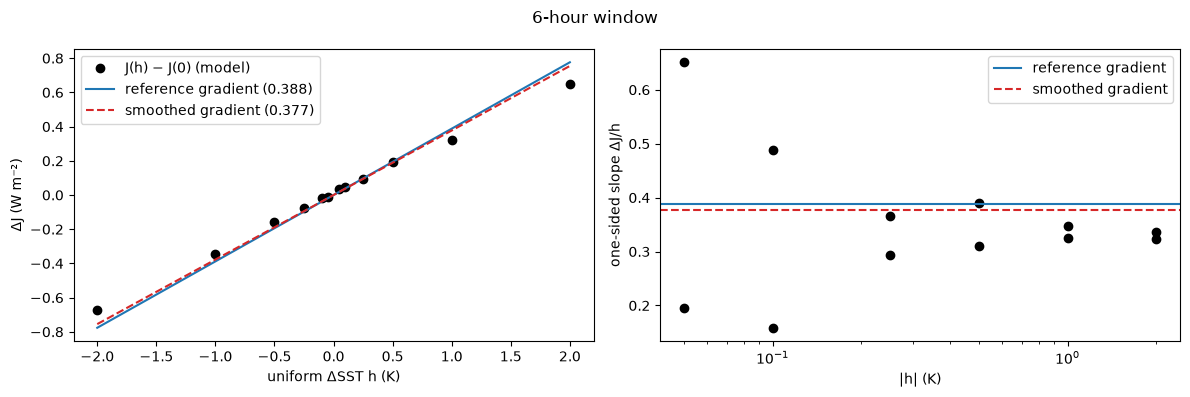

In [22]:
h_scan = np.array([-2, -1, -0.5, -0.25, -0.1, -0.05, 0.05, 0.1, 0.25, 0.5, 1, 2])
dJ_scan = np.array([float(J_ref(h * uniform)) - J0 for h in h_scan])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h_scan, dJ_scan, "ko", label="J(h) − J(0) (model)")
hh = np.linspace(-2, 2, 50)
ax[0].plot(hh, dJ_ref * hh, "C0-", label=f"reference gradient ({dJ_ref:.3f})")
ax[0].plot(hh, dJ_sm * hh, "C3--", label=f"smoothed gradient ({dJ_sm:.3f})")
ax[0].set_xlabel("uniform ΔSST h (K)"); ax[0].set_ylabel("ΔJ (W m⁻²)"); ax[0].legend()
ax[1].semilogx(np.abs(h_scan), dJ_scan / h_scan, "ko")
ax[1].axhline(dJ_ref, color="C0", label="reference gradient")
ax[1].axhline(dJ_sm, color="C3", ls="--", label="smoothed gradient")
ax[1].set_xlabel("|h| (K)"); ax[1].set_ylabel("one-sided slope ΔJ/h"); ax[1].legend()
plt.suptitle(f"{WINDOW*24:.0f}-hour window"); plt.tight_layout(); plt.show()

## 3. Sweep the smoothing width

If the gap comes from switches, the gradient should move toward the finite difference as the width grows. (The largest widths may overshoot, since the surrogate then describes a much smoother model than SPEEDY actually is.) Each new width builds a new model, so each one compiles once (about a minute).

width  0.00: dJ_uniform = 0.38815
width  0.01: dJ_uniform = 0.39726
width  0.05: dJ_uniform = 0.37739
width  0.10: dJ_uniform = 0.37876
width  0.20: dJ_uniform = 0.37969


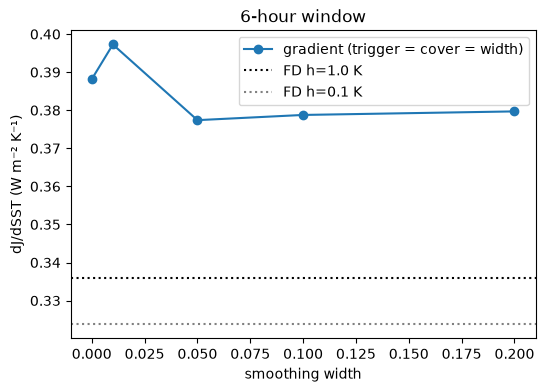

In [23]:
widths = [0.0, 0.01, 0.05, 0.1, 0.2]
sweep = {}
for wdt in widths:
    J_w = make_J(make_model(wdt, wdt), WINDOW)
    sweep[wdt] = float(jax.jvp(J_w, (zero,), (uniform,))[1])
    print(f"width {wdt:5.2f}: dJ_uniform = {sweep[wdt]:.5f}")

plt.figure(figsize=(6, 4))
plt.plot(widths, list(sweep.values()), "o-", label="gradient (trigger = cover = width)")
for h in [1.0, 0.1]:
    plt.axhline(fds[h], ls=":", color="k" if h == 1 else "gray", label=f"FD h={h} K")
plt.xlabel("smoothing width"); plt.ylabel("dJ/dSST (W m⁻² K⁻¹)"); plt.legend()
plt.title("6-hour window"); plt.show()

### Which switch matters?

Turn the two on separately, then add the other fraction-unit switches (condensation cap, shallow-convection RH gate). The widths of the unit-ful switches (`precnv`, `mse_gate`, `evap`) are left at 0, because a sensible width for them needs physical judgment. Try them yourself if you have time.

In [24]:
configs = {
    "trigger only (0.05)": make_model(0.05, 0.0),
    "cover only (0.05)":   make_model(0.0, 0.05),
    "both (0.05)":         model_smooth,
    "both + cap + rh_gate (0.05)": make_model(0.05, 0.05, extra={
        "condensation": {"cap_smoothing": 0.05},
        "vertical_diffusion": {"rh_gate_smoothing": 0.05}}),
}
by_switch = {}
for name, m in configs.items():
    by_switch[name] = float(jax.jvp(make_J(m, WINDOW), (zero,), (uniform,))[1])
    print(f"{name:30s} dJ = {by_switch[name]:.5f}   "
          f"(vs FD h=1: {100*(fds[1.0]-by_switch[name])/by_switch[name]:+.1f}%)")

trigger only (0.05)            dJ = 0.37512   (vs FD h=1: -10.5%)
cover only (0.05)              dJ = 0.39135   (vs FD h=1: -14.2%)
both (0.05)                    dJ = 0.37739   (vs FD h=1: -11.0%)
both + cap + rh_gate (0.05)    dJ = 0.37935   (vs FD h=1: -11.5%)


### Smoothing the remaining unit-ful switches

Does smoothing the switches still at zero width close the remaining ~11% gap? Widths are chosen from physical scales:
- `precnv_smoothing` is in g m⁻² s⁻¹. 1 mm/day of rain ≈ 0.0116 g m⁻² s⁻¹, so 0.01 ≈ 1 mm/day and 0.05 ≈ 4 mm/day.
- `mse_gate_smoothing` is in J kg⁻¹. c_p ≈ 1004 J kg⁻¹ K⁻¹, so 500 J/kg ≈ 0.5 K of dry static energy and 2000 J/kg ≈ 2 K.

`evap_smoothing` is left at 0 because it acts only over land, and J here is driven by SST over the ocean.

In [25]:
all_fraction = {"condensation": {"cap_smoothing": 0.05},
                "vertical_diffusion": {"rh_gate_smoothing": 0.05}}
unitful_configs = {
    "all + precnv 0.01, mse 500": {**all_fraction,
        "convection": {"precnv_smoothing": 0.01},
        "vertical_diffusion": {"rh_gate_smoothing": 0.05, "mse_gate_smoothing": 500.0}},
    "all + precnv 0.05, mse 2000": {**all_fraction,
        "convection": {"precnv_smoothing": 0.05},
        "vertical_diffusion": {"rh_gate_smoothing": 0.05, "mse_gate_smoothing": 2000.0}},
}
for name, extra in unitful_configs.items():
    m = make_model(0.05, 0.05, extra=extra)
    J_u = make_J(m, WINDOW)
    assert float(J_u(zero)) == J0, "values changed -- smoothing should not change J"
    by_switch[name] = float(jax.jvp(J_u, (zero,), (uniform,))[1])
    print(f"{name:30s} dJ = {by_switch[name]:.5f}   "
          f"(vs FD h=1: {100*(fds[1.0]-by_switch[name])/by_switch[name]:+.1f}%)")

all + precnv 0.01, mse 500     dJ = 0.35434   (vs FD h=1: -5.2%)
all + precnv 0.05, mse 2000    dJ = 0.36764   (vs FD h=1: -8.7%)


## 4. Longer windows

Task 4 found the gap grows with the window (about 2.3× at 1 day). Repeat for 1, 2 and 4 days with and without smoothing. If smoothing fixes the 6-hour gap but not the multi-day one, the long-window problem is something else, most likely the growth of perturbations in a chaotic flow: the tangent-linear model is only valid while perturbations stay small and linear.

W=0.25 d  grad_ref=  0.3881  grad_smooth=  0.3774  FD1=  0.3358  FD0.1=  0.3237
W=1.00 d  grad_ref=  0.4736  grad_smooth=  0.4645  FD1=  0.2453  FD0.1=  0.1997
W=2.00 d  grad_ref=  0.6050  grad_smooth=  0.6078  FD1=  0.2196  FD0.1=  0.1257
W=4.00 d  grad_ref=  0.8439  grad_smooth=  0.8497  FD1=  0.2578  FD0.1=  0.2861


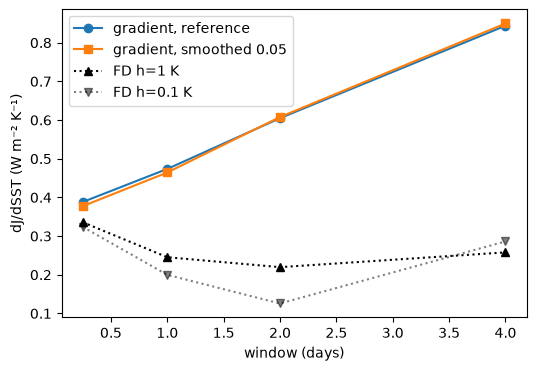

In [26]:
rows = []
for W in [0.25, 1.0, 2.0, 4.0]:
    Jr, Js = make_J(model_ref, W), make_J(model_smooth, W)
    g_ref = float(jax.jvp(Jr, (zero,), (uniform,))[1])
    g_sm  = float(jax.jvp(Js, (zero,), (uniform,))[1])
    f1, f01 = float(fd(Jr, 1.0)), float(fd(Jr, 0.1))
    rows.append((W, g_ref, g_sm, f1, f01))
    print(f"W={W:4.2f} d  grad_ref={g_ref:8.4f}  grad_smooth={g_sm:8.4f}  FD1={f1:8.4f}  FD0.1={f01:8.4f}")

rows = np.array(rows)
plt.figure(figsize=(6, 4))
plt.plot(rows[:, 0], rows[:, 1], "o-", label="gradient, reference")
plt.plot(rows[:, 0], rows[:, 2], "s-", label="gradient, smoothed 0.05")
plt.plot(rows[:, 0], rows[:, 3], "k^:", label="FD h=1 K")
plt.plot(rows[:, 0], rows[:, 4], "kv:", alpha=.5, label="FD h=0.1 K")
plt.xlabel("window (days)"); plt.ylabel("dJ/dSST (W m⁻² K⁻¹)"); plt.legend(); plt.show()

## 5. Sensitivity maps: reference vs smoothed

Reverse mode on both models at 6 hours. Smoothing should mostly change the map in regions near convective or cloud thresholds (the edges of the tropical convergence zones and the stratocumulus decks). Run the dot-product test on the smoothed model too: forward and reverse mode must still agree with each other.

dot-product test (smoothed): sum(map*1) = 0.37739  jvp = 0.37739


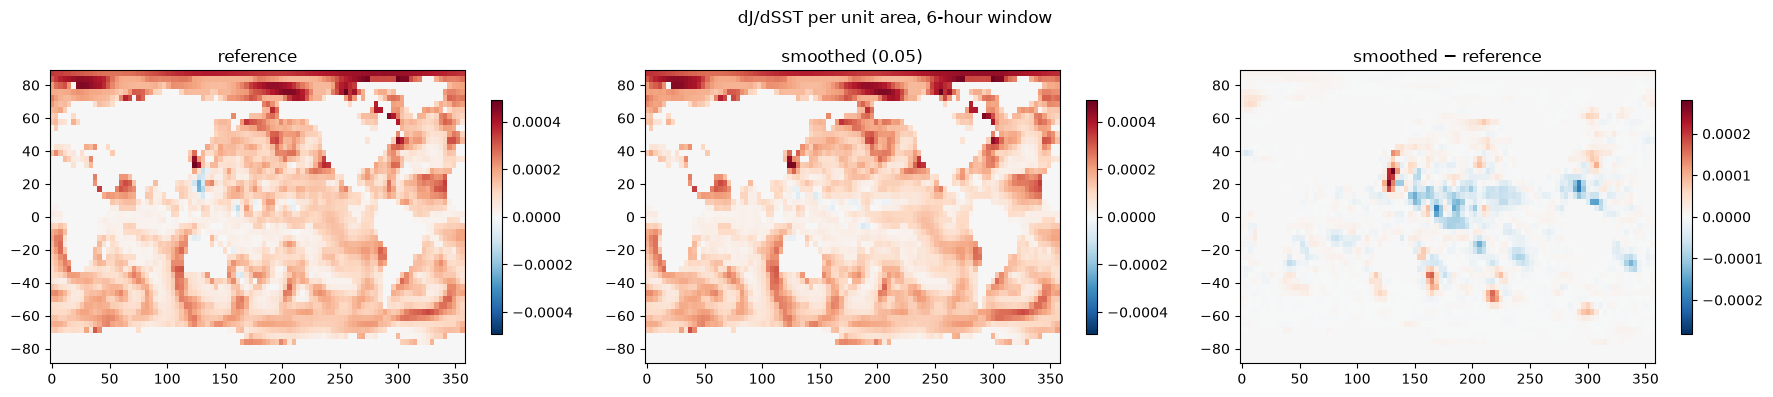

pattern correlation over ocean: 0.960
norms: ref=0.0085  smooth=0.0082


In [27]:
def sens_map(J):
    _, back = jax.vjp(J, zero)
    return back(1.0)[0]

smap_ref = sens_map(J_ref)
smap_sm  = sens_map(J_smooth)

print("dot-product test (smoothed):",
      f"sum(map*1) = {float(jnp.sum(smap_sm*uniform)):.5f}  jvp = {dJ_sm:.5f}")

per_area = lambda m: np.asarray(m / weights).T
maps = [per_area(smap_ref), per_area(smap_sm), per_area(smap_sm) - per_area(smap_ref)]
titles = ["reference", "smoothed (0.05)", "smoothed − reference"]
fig, axs = plt.subplots(1, 3, figsize=(18, 4))
v = np.nanmax(np.abs(maps[0]))
for a, m, t in zip(axs, maps, titles):
    vv = v if t != titles[2] else np.nanmax(np.abs(m))
    pc = a.pcolormesh(lon, lat, m, cmap="RdBu_r", vmin=-vv, vmax=vv)
    a.set_title(t); plt.colorbar(pc, ax=a, shrink=.8)
plt.suptitle("dJ/dSST per unit area, 6-hour window"); plt.tight_layout(); plt.show()

oc = np.asarray(ocean).T
r = np.corrcoef(maps[0][oc], maps[1][oc])[0, 1]
print(f"pattern correlation over ocean: {r:.3f}")
print(f"norms: ref={float(jnp.linalg.norm(smap_ref)):.4f}  smooth={float(jnp.linalg.norm(smap_sm)):.4f}")

## 6. Findings

1. **Does the gap shrink with smoothing?**
Smoothing leaves the model's values unchanged: J(0) and J(1 K) are identical to the bit. Only the derivative changes.
At 6 hours, smoothing both switches at 0.05 lowers the gradient from 0.388 to 0.377 W m⁻² K⁻¹. The gap to the finite difference (0.336 at h = 1 K) narrows only from about 13.5% to about 11%.
Widening the smoothing past 0.05 doesn't help: 0.10 gives 0.379 and 0.20 gives 0.380. The gradient levels off near 0.38, above the finite difference.
The J(h) plot is close to a straight line with slope about 0.33 for h between 0.25 and 2 K. So the gap isn't nonlinearity at large h: the finite difference agrees with itself across step sizes, and the gradient is the one that's off.

2. **Which switch is responsible?**
Almost all of the improvement comes from the convection trigger (trigger only: 0.375). Smoothing the cloud cover alone makes it slightly worse (0.391).
Also smoothing the condensation cap and the shallow-convection humidity gate changes almost nothing (0.379).
(Add the result of the new cells here.)

3. **If the gap does not close, what else could explain it?**
Hard switches with no smoothing parameter, for example where SST meets sea ice near freezing. The largest sensitivities sit at high-latitude ice edges, and smoothing doesn't change them at all.
Finite differences at small steps are unreliable. For h ≤ 0.1 K they scatter from 0.16 to 0.65. These jumps in J (about 0.01 W m⁻²) are far larger than float32 round-off on J itself (about 3×10⁻⁵), so the cause is probably individual columns crossing switches, plus round-off that grows over the time steps. The usable finite difference needs h ≥ 0.25 K, and over that range it measures a response averaged over many switch crossings that the exact derivative can't see.
Chaos at longer windows. From 6 hours to 4 days the gradient grows from 0.39 to 0.84 while the finite difference falls to 0.2–0.3. At 2 days the h = 1 and h = 0.1 finite differences disagree (0.22 vs 0.13). Smoothing changes the gradient by under 2% at every window. So at long windows the gap comes from small perturbations growing chaotically, and the linearization stops applying. Smoothing can't fix that.
A smoothed gradient is not the true derivative. It's the derivative of a slightly different, smoother model, so it can overshoot as well as close the gap. You can see this at width 0.01, where the gradient goes up to 0.397.

4. **How the maps change**
The overall pattern is the same: the correlation over ocean is 0.96, and the norm drops slightly (0.0085 → 0.0082).
The differences are in tropical deep-convection regions, mainly the western and central Pacific warm pool, where smoothing lowers the sensitivity. That fits the convection trigger being the switch that matters.
The high-latitude hotspots are unchanged.
The dot-product test still holds on the smoothed model (0.37739 both ways), so forward and reverse mode agree with each other.
